# Preprocessing C — Feature engineering

## Idea
Start from **approach A** and add features that combine several raw columns into one more meaningful value
(total size, age, number of bathrooms, ...). Trees can only split on one feature at a time, so a sum like
"basement + 1st floor + 2nd floor area" would otherwise need many splits to approximate.

Everything else is identical to A, so any difference in the results in `02_compare_preprocessing.ipynb` comes from the new features.
The original columns are kept; the comparison shows whether the new features add information.

**Input:** `processed_data/A_baseline.csv` (run `01_prep_A_baseline.ipynb` first)
**Output:** `processed_data/C_feature_engineering.csv`

## Steps

### 1. Load approach A

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from common import PROCESSED_DIR, TARGET, save_processed

df = pd.read_csv(PROCESSED_DIR / "A_baseline.csv")
print(df.shape)

(2930, 202)


### 2. New features

| Feature | Formula | Why |
|---|---|---|
| `Total SF` | basement + 1st floor + 2nd floor area | total living space is the main price driver |
| `Total Bathrooms` | full + ½ half baths, above ground and in the basement | four columns describe one thing |
| `House Age` | year sold − year built | buyers think in age, not in construction year |
| `Years Since Remod` | year sold − year of remodel | how "fresh" the house is |
| `Was Remodeled` | 1 if remodel year ≠ construction year | remodelled vs. original |
| `Total Porch SF` | wood deck + open, enclosed, 3-season and screen porch | five small, sparse columns → one |
| `Quality x SF` | overall quality × total area | a large *and* high-quality house is worth more than either alone |

A few new houses were sold before construction or remodelling was finished (year sold < year built), so the ages are clipped at 0.

In [2]:
total_sf = df["Total Bsmt SF"] + df["1st Flr SF"] + df["2nd Flr SF"]
new_features = pd.DataFrame({
    "Total SF": total_sf,
    "Total Bathrooms": df["Full Bath"] + 0.5 * df["Half Bath"] + df["Bsmt Full Bath"] + 0.5 * df["Bsmt Half Bath"],
    "House Age": (df["Yr Sold"] - df["Year Built"]).clip(lower=0),
    "Years Since Remod": (df["Yr Sold"] - df["Year Remod/Add"]).clip(lower=0),
    "Was Remodeled": (df["Year Remod/Add"] != df["Year Built"]).astype(int),
    "Total Porch SF": df[["Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch"]].sum(axis=1),
    "Quality x SF": df["Overall Qual"] * total_sf,
})
df = pd.concat([df, new_features], axis=1)

new_cols = new_features.columns.tolist()
df[new_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Total SF,2930.0,2546.269283,804.350838,334.0,2000.0,2450.0,2990.00,11752.0
Total Bathrooms,2930.0,2.217918,0.807444,1.0,1.5,2.0,2.50,7.0
House Age,2930.0,36.434471,30.290941,0.0,7.0,34.0,54.00,136.0
Years Since Remod,2930.0,23.525256,20.857256,0.0,4.0,15.0,42.75,60.0
Was Remodeled,2930.0,0.464505,0.498824,0.0,0.0,0.0,1.00,1.0
Total Porch SF,2930.0,182.891468,159.834420,0.0,48.0,165.0,266.00,1424.0
Quality x SF,2930.0,16269.930717,8489.532998,334.0,10400.0,14425.0,20063.50,117520.0


### 3. Do the new features carry information?
Spearman correlation with `PriceClass` (rank-based, suitable for an ordered target), compared with the columns they were built from.
A new feature that correlates more strongly than each of its parts is a sign it adds information.

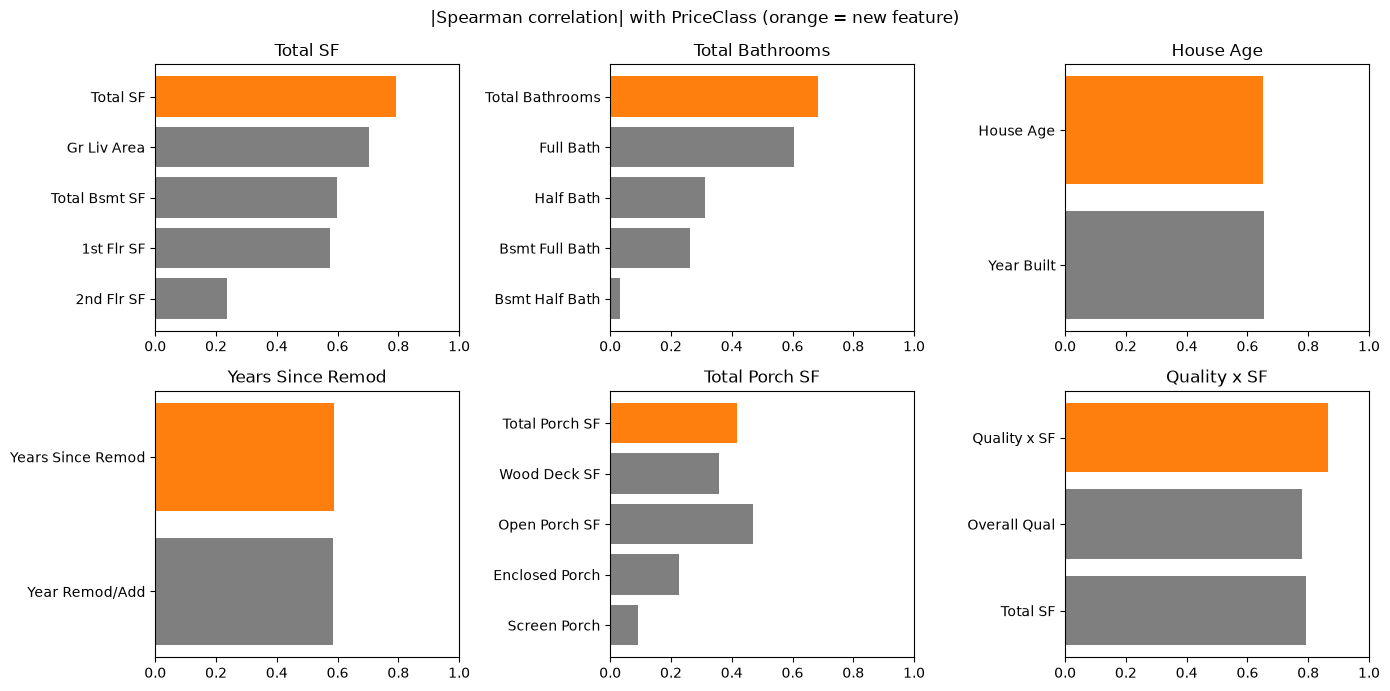

Quality x SF         0.866
Total SF             0.793
Total Bathrooms      0.684
House Age           -0.653
Years Since Remod   -0.589
Total Porch SF       0.416
Was Remodeled       -0.080
Name: PriceClass, dtype: float64

In [3]:
compare = {
    "Total SF": ["Total SF", "Gr Liv Area", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF"],
    "Total Bathrooms": ["Total Bathrooms", "Full Bath", "Half Bath", "Bsmt Full Bath", "Bsmt Half Bath"],
    "House Age": ["House Age", "Year Built"],
    "Years Since Remod": ["Years Since Remod", "Year Remod/Add"],
    "Total Porch SF": ["Total Porch SF", "Wood Deck SF", "Open Porch SF", "Enclosed Porch", "Screen Porch"],
    "Quality x SF": ["Quality x SF", "Overall Qual", "Total SF"],
}
corr = df.corr(method="spearman", numeric_only=True)[TARGET]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (feature, cols) in zip(axes.flat, compare.items()):
    values = corr[cols].abs()
    ax.barh(cols[::-1], values[::-1], color=["tab:gray"] * (len(cols) - 1) + ["tab:orange"])
    ax.set_xlim(0, 1); ax.set_title(feature)
fig.suptitle(f"|Spearman correlation| with {TARGET} (orange = new feature)")
fig.tight_layout()
plt.show()

corr[new_cols].sort_values(key=abs, ascending=False).round(3)

**Interpretation**
- `Quality x SF` (0.87) and `Total SF` (0.79) are stronger than any of their parts (`Overall Qual` 0.78, `Gr Liv Area` 0.71) — they add information.
- `Total Bathrooms` (0.68) beats `Full Bath` (0.61), the strongest bathroom column.
- `House Age` and `Years Since Remod` are almost identical to `Year Built` / `Year Remod/Add`: houses were sold within 5 years (2006–2010),
  so age is mostly the construction year flipped. They mainly make the trees easier to read.
- `Total Porch SF` (0.42) is *weaker* than `Open Porch SF` alone (0.47): summing mixes porch types with different value.
- `Was Remodeled` is weak on its own; trees can still combine it with other features.

Correlation only looks at one feature at a time; the real test is the model comparison in `02_compare_preprocessing.ipynb`.

## Output saved

In [4]:
assert df.select_dtypes(exclude="number").empty, "all features must be numeric"

path = save_processed(df, "C_feature_engineering")
print(f"Saved {df.shape[0]} rows x {df.shape[1] - 1} features (+ {TARGET}) to {path.name}")
print(f"{len(new_cols)} new features:", new_cols)

Saved 2930 rows x 208 features (+ PriceClass) to C_feature_engineering.csv
7 new features: ['Total SF', 'Total Bathrooms', 'House Age', 'Years Since Remod', 'Was Remodeled', 'Total Porch SF', 'Quality x SF']


**Summary:** approach A + 7 engineered features, same 2930 houses and same target.